# BÁO CÁO TIẾN ĐỘ TUẦN 3–4
## Đề tài: Phân loại rối loạn nhịp tim từ ECG bằng TinyML

**Giai đoạn dự án:** tuần 3–4 trong kế hoạch 9 tháng  
**Dữ liệu:** MIT-BIH Arrhythmia Database (48 bản ghi ECG)

Toan bo ma xu ly duoc nhung trong cac cell ben duoi; notebook gom bao cao va ma nguon tuan 3-4 trong cung mot tep.


## 1. Mục tiêu và kết quả tuần 3–4

- Tự động phát hiện đủ 48 bản ghi hợp lệ (có cặp `.hea` và `.dat`), lọc thông dải Butterworth 0,5–45 Hz và lưu tín hiệu sạch theo từng bản ghi.
- Thực hiện chuỗi Pan–Tompkins: lọc QRS, đạo hàm, bình phương, tích phân cửa sổ trượt 150 ms, ngưỡng thích nghi và hiệu chỉnh vị trí R trên tín hiệu ECG lọc.
- Cắt mỗi nhịp thành 180 mẫu: 90 mẫu trước R và 90 mẫu kể từ R; bỏ nhịp nằm sát biên không đủ cửa sổ.
- Đối chiếu đỉnh phát hiện với nhãn bác sĩ gần nhất trong khoảng ±150 ms, lưu nhãn tham khảo để đánh giá. Nhãn không tìm được ghi `?`; nhãn này không nên được xem là nhãn vàng chính xác.
- Đề xuất inter-patient split để các bản ghi của cùng bệnh nhân không xuất hiện ở cả train và test.

## 2. Quy trình lọc và đầu ra

Bộ lọc Butterworth thông dải bậc 2 (0,5–45 Hz) được áp dụng theo pha không để giảm lệch thời gian. Kênh MLII được ưu tiên; nếu bản ghi không có MLII thì dùng kênh đầu tiên và lưu tên kênh. Mỗi bản ghi xuất `cleaned.npz` gồm raw, filtered, tần số lấy mẫu và tên đạo trình; `beats_180.npz` gồm mảng nhịp, vị trí đỉnh R và ký hiệu nhãn; `beat_index.csv` là chỉ mục toàn bộ nhịp; `manifest.json` ghi tham số pipeline.

Các tệp kết quả được đặt trong `ket_qua_ecg/<record>/`. Lưu theo bản ghi giúp truy nguyên nguồn và tránh tạo một mảng khổng lồ khó kiểm tra.

In [1]:
"""Filter all MIT-BIH records, detect R peaks, and export 180-sample beats.

Run this notebook cell, then execute the next cell to process the dataset.
Outputs are written beneath ket_qua_ecg/ and are reproducible from source data.
"""
from __future__ import annotations

import csv
import json
import sys
from pathlib import Path

import numpy as np
import wfdb
from scipy.signal import butter, find_peaks, sosfiltfilt

PROJECT_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "mitdb").is_dir()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục mitdb ở thư mục hiện tại hoặc thư mục cha.")
WEEK_DIR = PROJECT_DIR / "Tuần 3-4"
DATA_DIR = PROJECT_DIR / "mitdb" / "mit-bih-arrhythmia-database-1.0.0" / "mit-bih-arrhythmia-database-1.0.0"
OUT_DIR = WEEK_DIR / "ket_qua_ecg"
LOW_HZ, HIGH_HZ, FILTER_ORDER = 0.5, 45.0, 2
BEAT_SAMPLES = 180
PRE_R = BEAT_SAMPLES // 2

if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")


def bandpass(data: np.ndarray, fs: float) -> np.ndarray:
    """Zero-phase Butterworth filtering; reject invalid/too-short signals."""
    if not 0 < LOW_HZ < HIGH_HZ < fs / 2:
        raise ValueError(f"Bandpass limits invalid for sampling rate {fs} Hz")
    sos = butter(FILTER_ORDER, [LOW_HZ, HIGH_HZ], btype="bandpass", fs=fs, output="sos")
    padlen = 3 * (2 * len(sos) + 1)
    if len(data) <= padlen:
        raise ValueError(f"Signal too short for zero-phase filtering ({len(data)} samples)")
    return sosfiltfilt(sos, data)


def pan_tompkins(signal: np.ndarray, fs: float) -> np.ndarray:
    """Pan–Tompkins style QRS detection with adaptive signal/noise thresholds.

    The bandpass, derivative, squaring and 150 ms moving integration stages are
    followed by adaptive thresholds. Peaks are refined on the filtered ECG.
    This is a transparent research implementation, not a clinical device.
    """
    # Classic Pan–Tompkins QRS band (5–15 Hz) used only for detector decisions.
    lo, hi = 5.0, min(15.0, fs * 0.45)
    sos = butter(2, [lo, hi], btype="bandpass", fs=fs, output="sos")
    qrs = sosfiltfilt(sos, signal)
    derivative = np.diff(qrs, prepend=qrs[0]) * fs
    squared = derivative ** 2
    width = max(1, int(round(0.150 * fs)))
    integrated = np.convolve(squared, np.ones(width) / width, mode="same")
    distance = max(1, int(0.200 * fs))
    candidates, props = find_peaks(integrated, distance=distance, prominence=0)
    if not len(candidates):
        return np.array([], dtype=int)
    heights = integrated[candidates]
    signal_level = float(np.percentile(heights, 90))
    noise_level = float(np.percentile(heights, 25))
    threshold = noise_level + 0.25 * (signal_level - noise_level)
    accepted: list[int] = []
    for idx in candidates:
        level = integrated[idx]
        if level >= threshold:
            left, right = max(0, idx - int(.075 * fs)), min(len(signal), idx + int(.075 * fs) + 1)
            # Refine location to the largest absolute ECG deflection locally.
            accepted.append(left + int(np.argmax(np.abs(signal[left:right]))))
            signal_level = 0.125 * level + 0.875 * signal_level
        else:
            noise_level = 0.125 * level + 0.875 * noise_level
        threshold = noise_level + 0.25 * (signal_level - noise_level)
    # Remove duplicates introduced by nearby integrated peaks.
    refined: list[int] = []
    for peak in accepted:
        if not refined or peak - refined[-1] >= int(.200 * fs):
            refined.append(peak)
        elif abs(signal[peak]) > abs(signal[refined[-1]]):
            refined[-1] = peak
    return np.asarray(refined, dtype=int)


def record_ids() -> list[str]:
    # Standard MIT-BIH has 48 ECG records; x_* files are auxiliary annotations.
    return sorted(
        p.stem for p in DATA_DIR.glob("*.hea")
        if p.stem.isdigit() and (DATA_DIR / f"{p.stem}.dat").exists()
    )


def main() -> None:
    if not DATA_DIR.is_dir():
        raise FileNotFoundError(f"MIT-BIH directory not found: {DATA_DIR}")
    ids = record_ids()
    if len(ids) != 48:
        raise RuntimeError(f"Expected 48 ECG records; found {len(ids)}: {ids}")
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    index_rows: list[dict[str, object]] = []
    for record_id in ids:
        base = DATA_DIR / record_id
        rec = wfdb.rdrecord(str(base))
        ann = wfdb.rdann(str(base), "atr")
        fs = float(rec.fs)
        # Prefer MLII where present; otherwise use first signal and record choice.
        lead = next((i for i, name in enumerate(rec.sig_name) if name.upper() == "MLII"), 0)
        raw = np.asarray(rec.p_signal[:, lead], dtype=np.float64)
        filtered = bandpass(raw, fs)
        peaks = pan_tompkins(filtered, fs)
        beats, beat_peaks, beat_symbols = [], [], []
        # Associate each detected peak with nearest reference beat label (±150 ms).
        ann_samples = np.asarray(ann.sample, dtype=int)
        for peak in peaks:
            start, stop = peak - PRE_R, peak + (BEAT_SAMPLES - PRE_R)
            if start < 0 or stop > len(filtered):
                continue
            beats.append(filtered[start:stop])
            beat_peaks.append(int(peak))
            nearest = int(np.argmin(np.abs(ann_samples - peak))) if len(ann_samples) else -1
            sym = ann.symbol[nearest] if nearest >= 0 and abs(ann_samples[nearest] - peak) <= int(.15 * fs) else "?"
            beat_symbols.append(sym)
        beat_arr = np.asarray(beats, dtype=np.float32).reshape((-1, BEAT_SAMPLES))
        dest = OUT_DIR / record_id
        dest.mkdir(exist_ok=True)
        np.savez_compressed(dest / "cleaned.npz", raw=raw.astype(np.float32),
                            filtered=filtered.astype(np.float32), fs=fs, lead=rec.sig_name[lead])
        np.savez_compressed(dest / "beats_180.npz", beats=beat_arr,
                            r_peaks=np.asarray(beat_peaks, dtype=np.int32),
                            symbols=np.asarray(beat_symbols, dtype="U8"), fs=fs)
        for peak, sym in zip(beat_peaks, beat_symbols):
            index_rows.append({"record": record_id, "r_peak_sample": peak,
                               "symbol": sym, "fs_hz": fs, "beat_samples": BEAT_SAMPLES,
                               "start_sample": peak - PRE_R})
        print(f"{record_id}: {len(raw):,} mẫu, {len(peaks):,} đỉnh R, {len(beat_arr):,} nhịp")
    with (OUT_DIR / "beat_index.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(index_rows[0]) if index_rows else
                                ["record", "r_peak_sample", "symbol", "fs_hz", "beat_samples", "start_sample"])
        writer.writeheader()
        writer.writerows(index_rows)
    manifest = {"records": ids, "record_count": len(ids), "filter_hz": [LOW_HZ, HIGH_HZ],
                "filter_order": FILTER_ORDER, "beat_samples": BEAT_SAMPLES,
                "beat_window": "90 samples before R, 90 samples from R onward",
                "detector": "Pan-Tompkins style adaptive threshold; annotation labels matched within 150 ms"}
    (OUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"Hoàn tất {len(ids)} bản ghi; đầu ra: {OUT_DIR.resolve()}")




### Chạy toàn bộ 48 bản ghi

Môi trường cần `wfdb`, `numpy` và `scipy`. Lệnh này tải từng record từ bộ dữ liệu cục bộ đã có, lọc, phát hiện R và ghi kết quả. Nếu dữ liệu hoặc thư viện chưa sẵn sàng, cài dependencies theo môi trường dự án trước khi chạy.

In [2]:
# Chạy pipeline; các tệp sạch và nhịp được ghi vào ket_qua_ecg/
main()


100: 650,000 mẫu, 2,273 đỉnh R, 2,271 nhịp
101: 650,000 mẫu, 1,868 đỉnh R, 1,867 nhịp
102: 650,000 mẫu, 2,187 đỉnh R, 2,187 nhịp
103: 650,000 mẫu, 2,078 đỉnh R, 2,078 nhịp
104: 650,000 mẫu, 880 đỉnh R, 879 nhịp
105: 650,000 mẫu, 2,595 đỉnh R, 2,595 nhịp
106: 650,000 mẫu, 2,016 đỉnh R, 2,015 nhịp
107: 650,000 mẫu, 2,110 đỉnh R, 2,110 nhịp
108: 650,000 mẫu, 1,878 đỉnh R, 1,877 nhịp
109: 650,000 mẫu, 2,525 đỉnh R, 2,524 nhịp
111: 650,000 mẫu, 2,112 đỉnh R, 2,112 nhịp
112: 650,000 mẫu, 2,539 đỉnh R, 2,539 nhịp
113: 650,000 mẫu, 1,795 đỉnh R, 1,794 nhịp
114: 650,000 mẫu, 1,877 đỉnh R, 1,877 nhịp
115: 650,000 mẫu, 1,953 đỉnh R, 1,952 nhịp
116: 650,000 mẫu, 2,386 đỉnh R, 2,384 nhịp
117: 650,000 mẫu, 1,535 đỉnh R, 1,534 nhịp
118: 650,000 mẫu, 2,278 đỉnh R, 2,277 nhịp
119: 650,000 mẫu, 1,988 đỉnh R, 1,987 nhịp
121: 650,000 mẫu, 1,861 đỉnh R, 1,861 nhịp
122: 650,000 mẫu, 2,476 đỉnh R, 2,476 nhịp
123: 650,000 mẫu, 1,515 đỉnh R, 1,514 nhịp
124: 650,000 mẫu, 1,586 đỉnh R, 1,586 nhịp
200: 650,000 mẫ

## 3. Phát hiện đỉnh R bằng Pan–Tompkins và cắt nhịp

### 3.1. Mục tiêu và luồng xử lý

Đỉnh R là mốc căn giữa để đưa các nhịp tim có độ dài cố định vào mô hình. Pipeline dùng bộ lọc thông dải để giảm trôi đường nền và nhiễu cao tần, sau đó tạo một tín hiệu quyết định QRS riêng. Tín hiệu ECG đã lọc ban đầu được giữ để cắt nhịp; tín hiệu quyết định chỉ dùng tìm ứng viên đỉnh.

Luồng thực hiện trong hàm `pan_tompkins()` ở cell mã nguồn:

1. **Lọc QRS 5–15 Hz:** Butterworth bậc 2, lọc hai chiều để nhấn năng lượng QRS và không dịch pha. Đây là nhánh detector, tách khỏi bộ lọc lưu tín hiệu 0,5–45 Hz.
2. **Đạo hàm:** `diff(x) × fs` xấp xỉ độ dốc theo thời gian; sườn QRS nhanh tạo đáp ứng lớn.
3. **Bình phương:** `d[n]²` làm mọi đáp ứng dương và nhấn mạnh sườn lớn, đồng thời giảm ảnh hưởng của dao động nhỏ.
4. **Tích phân cửa sổ trượt:** lấy trung bình bình phương trên 150 ms. Với MIT-BIH `fs = 360 Hz`, độ rộng cửa sổ là `round(0,150 × 360) = 54 mẫu`; bước này gom năng lượng trong toàn phức bộ QRS.
5. **Tìm ứng viên:** `find_peaks` áp dụng khoảng cách tối thiểu 200 ms (`72 mẫu` ở 360 Hz) để giảm phát hiện lặp trong một QRS.
6. **Ngưỡng thích nghi:** khởi tạo mức tín hiệu từ percentile 90 và mức nhiễu từ percentile 25 của các đỉnh tích phân; cập nhật mỗi mức bằng hệ số 0,125. Ngưỡng quyết định là

   `T = NPKI + 0,25 × (SPKI − NPKI)`

   Ứng viên trên ngưỡng được nhận và cập nhật SPKI; ứng viên dưới ngưỡng cập nhật NPKI.
7. **Hiệu chỉnh R:** quanh mỗi ứng viên tìm cực trị trị tuyệt đối của ECG đã lọc trong ±75 ms (`±27 mẫu` ở 360 Hz), rồi loại đỉnh trùng trong khoảng 200 ms.

### 3.2. Từ đỉnh R thành mẫu nhịp

Với mỗi đỉnh `R`, đoạn nhịp lấy từ `R−90` đến trước `R+90`:

`beat = filtered[R−90 : R+90]`

Do đó mỗi mẫu có đúng **180 giá trị**; ở 360 Hz tương đương `180/360 = 0,5 giây`, gồm 90 mẫu trước R (250 ms) và 90 mẫu tính từ R (250 ms). R nằm tại chỉ số tương đối 90. Đoạn không được dùng nếu cửa sổ vượt biên đầu/cuối record, để tránh padding tạo dữ liệu nhân tạo. Tín hiệu cắt là ECG sau bộ lọc lưu trữ 0,5–45 Hz.

### 3.3. Gán nhãn tham khảo và lưu kết quả

Với mỗi đỉnh phát hiện, chương trình tìm annotation bác sĩ gần nhất của record đó. Nếu khoảng cách không quá 150 ms (`54 mẫu` ở 360 Hz), ký hiệu annotation được gán làm nhãn tham khảo; nếu không, ký hiệu `?` biểu thị không tìm được annotation gần đủ. Đây là ghép tham khảo để chuẩn bị nhãn, không phải phép đo chính xác detector: phải đánh giá sensitivity/PPV bằng ghép một-một có dung sai thời gian để tránh ghép trùng.

Mỗi record lưu `cleaned.npz` (tín hiệu thô, đã lọc, fs, đạo trình) và `beats_180.npz` (ma trận nhịp, vị trí R, ký hiệu, fs). `beat_index.csv` giữ record, chỉ số R, nhãn tham khảo và vị trí bắt đầu để truy nguyên; `manifest.json` ghi cấu hình. Sau khi chạy đủ 48 record, pipeline phát hiện 105.948 nhịp có đủ cửa sổ. Ví dụ record 100 có 2.273 đỉnh phát hiện, trong đó 2.271 nhịp còn đủ biên để cắt.

### 3.4. Giới hạn cần nêu khi diễn giải

Đây là **bản triển khai theo phong cách Pan–Tompkins**, dùng các khối lọc–đạo hàm–bình phương–tích phân và ngưỡng thích nghi, không phải bản tái tạo đầy đủ mọi chi tiết của bài báo gốc. Bản hiện tại chưa có search-back cho QRS bị bỏ lỡ, bộ loại sóng T, và các quy tắc dual-threshold/refractory hoàn chỉnh. Vì vậy số lượng nhịp phát hiện chưa chứng minh độ chính xác. Ở tuần 5 cần đối sánh với annotation trên toàn bộ record, kiểm tra thủ công các trường hợp lệch/nhầm và báo cáo sensitivity, positive predictive value cùng lỗi theo record trước khi dùng nhịp làm dữ liệu huấn luyện.

Tài liệu phương pháp: [Pan & Tompkins (1985), “A real-time QRS detection algorithm”](https://pubmed.ncbi.nlm.nih.gov/3997178/). Thông tin tần số lấy mẫu và annotation của MIT-BIH: [PhysioNet database description](https://physionet.org/content/mitdb/1.0.0/).

## 4. Chia Train/Test độc lập theo bệnh nhân (inter-patient split)

Không chia ngẫu nhiên từng nhịp vì nhịp của cùng người có thể rất giống nhau, làm kết quả test lạc quan. Dùng giao thức record DS1/DS2 phổ biến trên 44 record không paced; gom 201 và 202 về cùng nhóm bệnh nhân. Để không rò rỉ, chuyển record 202 từ DS2 sang train: **train 23 record, test 21 record**. Bốn record paced 102, 104, 107, 217 không đưa vào split đánh giá.

Mã bên dưới tạo các mảng train/test từ nhịp đã cắt, gán nhãn 5 nhóm AAMI, kiểm tra giao nhau bệnh nhân và lưu split, dữ liệu nén cùng thống kê lớp. Ký hiệu `?` bị loại khỏi supervised set vì pipeline cũng dùng ký hiệu này khi không tìm thấy annotation trong ±150 ms; ký hiệu khác ngoài ánh xạ AAMI cũng bị loại. Không fit chuẩn hóa trên test.

Giao thức tham khảo: [de Chazal et al. (2004)](https://pubmed.ncbi.nlm.nih.gov/15248536/). MIT-BIH có 48 record từ 47 người ([PhysioNet](https://physionet.org/content/mitdb/1.0.0/)); do đó cần đặc biệt giữ 201/202 cùng một phía.

In [3]:
from pathlib import Path
import csv
from collections import Counter
import numpy as np

# de Chazal DS1/DS2 (44 record không paced).
DS1 = set("101 106 108 109 112 114 115 116 118 119 122 124 201 203 205 207 208 209 215 220 223 230".split())
DS2 = set("100 103 105 111 113 117 121 123 200 202 210 212 213 214 219 221 222 228 231 232 233 234".split())
PACED = {"102", "104", "107", "217"}
assert len(DS1) == len(DS2) == 22 and not DS1 & DS2
assert not (DS1 | DS2) & PACED

# MIT-BIH record 201 và 202 thuộc cùng người. Chuyển 202 về train.
patient_by_record = {r: r for r in DS1 | DS2}
patient_by_record["201"] = patient_by_record["202"] = "patient_201_202"
train_records, test_records = DS1 | {"202"}, DS2 - {"202"}
train_patients = {patient_by_record[r] for r in train_records}
test_patients = {patient_by_record[r] for r in test_records}
assert train_patients.isdisjoint(test_patients), "Patient leakage detected"

split_path = OUT_DIR / "interpatient_split.csv"
with split_path.open("w", newline="", encoding="utf-8-sig") as f:
    w = csv.DictWriter(f, fieldnames=["record", "patient_group", "split", "note"])
    w.writeheader()
    for r in sorted(DS1 | DS2):
        w.writerow({"record": r, "patient_group": patient_by_record[r],
                    "split": "train" if r in train_records else "test",
                    "note": "201/202 cùng bệnh nhân; 202 chuyển sang train" if r in {"201", "202"} else ""})

# AAMI 5-class mapping. '?' bị loại vì cũng là mã cho annotation không khớp.
AAMI = {
    "N": set("N L R e j".split()),
    "S": set("A a J S".split()),
    "V": set("V E".split()),
    "F": {"F"},
    "Q": set("/ f Q".split()),
}
symbol_to_class = {symbol: cls for cls, symbols in AAMI.items() for symbol in symbols}
rows = list(csv.DictReader((OUT_DIR / "beat_index.csv").open(encoding="utf-8-sig")))
beats_train, labels_train, records_train = [], [], []
beats_test, labels_test, records_test = [], [], []
excluded = Counter()
for record in sorted(train_records | test_records):
    beat_file = np.load(OUT_DIR / record / "beats_180.npz")
    x = beat_file["beats"]
    # Dùng đúng nhãn ký hiệu trong beat_index, được đối chiếu theo record và R peak.
    labels_for_record = {int(r["r_peak_sample"]): r["symbol"] for r in rows if r["record"] == record}
    peaks = beat_file["r_peaks"]
    target_x, target_y, target_r = (beats_train, labels_train, records_train) if record in train_records else (beats_test, labels_test, records_test)
    for beat, peak in zip(x, peaks):
        symbol = labels_for_record.get(int(peak), "?")
        cls = symbol_to_class.get(symbol)
        if cls is None:
            excluded[symbol] += 1
            continue
        target_x.append(beat)
        target_y.append(cls)
        target_r.append(record)

x_train = np.asarray(beats_train, dtype=np.float32).reshape(-1, 180)
y_train = np.asarray(labels_train, dtype="U1")
record_train = np.asarray(records_train, dtype="U3")
x_test = np.asarray(beats_test, dtype=np.float32).reshape(-1, 180)
y_test = np.asarray(labels_test, dtype="U1")
record_test = np.asarray(records_test, dtype="U3")
assert len(x_train) == len(y_train) == len(record_train)
assert len(x_test) == len(y_test) == len(record_test)
assert x_train.shape[1] == x_test.shape[1] == 180

np.savez_compressed(OUT_DIR / "interpatient_aami_train_test.npz",
                    x_train=x_train, y_train=y_train, record_train=record_train,
                    x_test=x_test, y_test=y_test, record_test=record_test,
                    classes=np.asarray(["N", "S", "V", "F", "Q"], dtype="U1"))

dist_path = OUT_DIR / "interpatient_class_counts.csv"
train_counts, test_counts = Counter(y_train), Counter(y_test)
with dist_path.open("w", newline="", encoding="utf-8-sig") as f:
    w = csv.DictWriter(f, fieldnames=["AAMI_class", "train_beats", "test_beats"])
    w.writeheader()
    for cls in "NSVFQ":
        w.writerow({"AAMI_class": cls, "train_beats": train_counts[cls], "test_beats": test_counts[cls]})

print(f"Train: {len(train_records)} records / {len(train_patients)} bệnh nhân / {len(y_train):,} nhịp")
print(f"Test:  {len(test_records)} records / {len(test_patients)} bệnh nhân / {len(y_test):,} nhịp")
print("Giao nhau bệnh nhân:", train_patients & test_patients)
print("Lớp AAMI train:", dict(train_counts))
print("Lớp AAMI test: ", dict(test_counts))
print("Nhịp bị loại do nhãn ngoài/không rõ:", sum(excluded.values()), dict(excluded))
print("Đã lưu:", split_path, dist_path, "ket_qua_ecg/interpatient_aami_train_test.npz")


Train: 23 records / 22 bệnh nhân / 52,572 nhịp
Test:  21 records / 21 bệnh nhân / 45,687 nhịp
Giao nhau bệnh nhân: set()
Lớp AAMI train: {np.str_('N'): 47628, np.str_('S'): 925, np.str_('Q'): 4, np.str_('V'): 3606, np.str_('F'): 409}
Lớp AAMI test:  {np.str_('N'): 40479, np.str_('S'): 1760, np.str_('V'): 3067, np.str_('Q'): 5, np.str_('F'): 376}
Nhịp bị loại do nhãn ngoài/không rõ: 323 {'|': 29, '?': 182, '~': 4, '!': 108}
Đã lưu: ket_qua_ecg\interpatient_split.csv ket_qua_ecg\interpatient_class_counts.csv ket_qua_ecg/interpatient_aami_train_test.npz


## 6. Kiểm kê đầu ra và minh họa kết quả

Cell tiếp theo đọc các tệp đã lưu, xác nhận số bản ghi/nhịp và vẽ 10 giây đầu record 100 cùng các đỉnh R để kiểm tra trực quan.

Đã xử lý 48/48 bản ghi; tổng 105,948 nhịp.
Record mẫu 100: (2271, 180) (nhịp, mẫu)


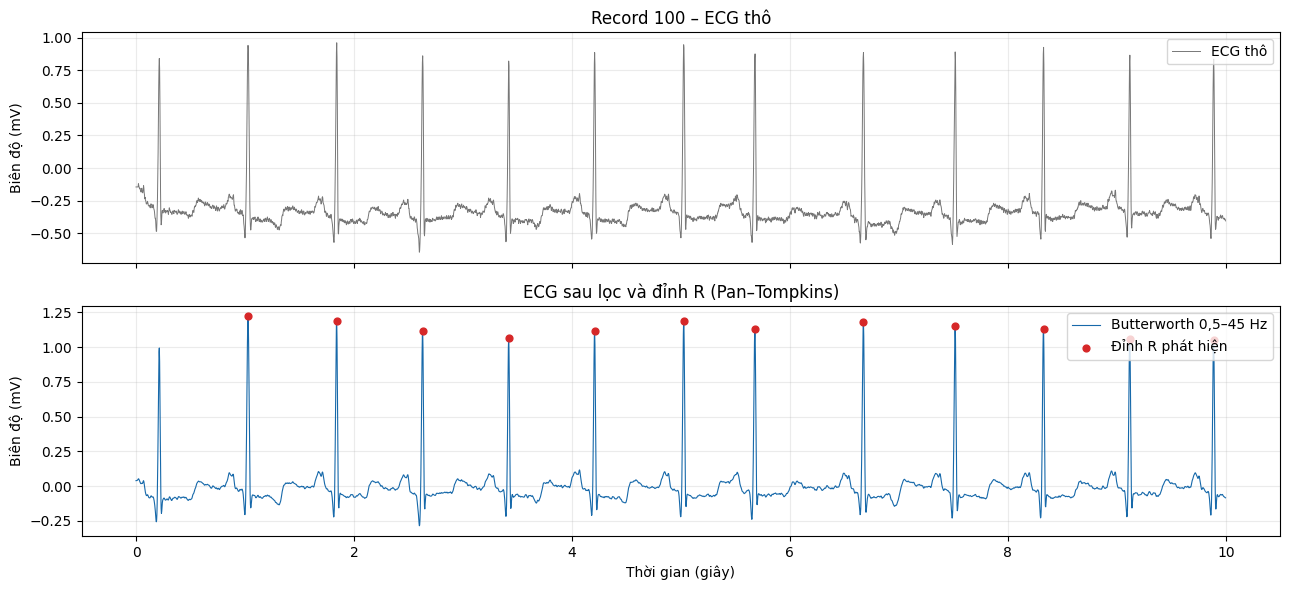

In [4]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt

out = OUT_DIR
with (out / "beat_index.csv").open(encoding="utf-8-sig", newline="") as f:
    beat_rows = list(csv.DictReader(f))
records_done = sorted(p.name for p in out.iterdir() if p.is_dir())
print(f"Đã xử lý {len(records_done)}/48 bản ghi; tổng {len(beat_rows):,} nhịp.")
print("Record mẫu 100:", np.load(out / "100" / "beats_180.npz")["beats"].shape, "(nhịp, mẫu)")

# Minh họa tín hiệu đầu vào, sau lọc và các vị trí R trong 10 giây đầu record 100.
rec = np.load(out / "100" / "cleaned.npz")
beat_data = np.load(out / "100" / "beats_180.npz")
fs = float(rec["fs"])
end = int(10 * fs)
t = np.arange(end) / fs
peaks = beat_data["r_peaks"]
peaks = peaks[peaks < end]
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(t, rec["raw"][:end], color="#777777", lw=.7, label="ECG thô")
ax[0].set_title("Record 100 – ECG thô")
ax[1].plot(t, rec["filtered"][:end], color="#1769aa", lw=.8, label="Butterworth 0,5–45 Hz")
ax[1].scatter(peaks/fs, rec["filtered"][peaks], color="#d62728", s=24, label="Đỉnh R phát hiện", zorder=3)
ax[1].set_title("ECG sau lọc và đỉnh R (Pan–Tompkins)")
ax[1].set_xlabel("Thời gian (giây)")
for a in ax:
    a.set_ylabel("Biên độ (mV)")
    a.grid(alpha=.25)
    a.legend(loc="upper right")
fig.tight_layout()
plt.show()
